## Current branch and cached evidence

This notebook executes bounded CPU smoke checks. Scientific plots below retain their original saved source, settings and qualification scope; they are not fits from this smoke run. The current independent production/testing default is **128 walkers /128 burn-in /256 retained, one ensemble**, with 2,048 draws for deterministic trend integration. Qualification still uses independent ensembles and diagnostic gates. See [VALIDATION_STATUS.md](VALIDATION_STATUS.md) and [EXECUTION_PROFILES.md](EXECUTION_PROFILES.md).

All six preset families have CPU/native MPS likelihood and trend-smoother checks. GPU production uses float32 automatically; CUDA hardware testing is pending. Historical float32 failures and short joint convergence flags remain. The API still selects registered presets; arbitrary composition is future work. Panel limits and the separate spatial/lag runtime-estimate and selection gates remain in force. No cached selection enables a new long fit automatically.

Timing charts in the older stage04 sections describe that historical implementation, before the structured GPU backend. Current measured CPU/GPU production timings are in [VALIDATION_STATUS.md](VALIDATION_STATUS.md).

In [1]:
from pathlib import Path
import hashlib, json
from dlmmc import PRODUCTION_PROFILE
current_bundle = Path.cwd() / "examples/modernization/current"
current_manifest = json.loads((current_bundle / "manifest.json").read_text())
for filename, expected in current_manifest["files"].items():
    assert hashlib.sha256((current_bundle / filename).read_bytes()).hexdigest() == expected
print("Current production profile:", PRODUCTION_PROFILE.to_dict())
print("Verified cached follow-up evidence files:", len(current_manifest["files"]))

Current production profile: {'name': 'production', 'runs': 1, 'half_walkers': 64, 'warmup': 128, 'retained_sweeps': 256, 'chunk_sweeps': 16, 'thin': 1, 'output_draws_per_sweep': 8}
Verified cached follow-up evidence files: 8


/Users/justin/Documents/projects/dlmmc-modernization/reports/19-cleanup/env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import json, hashlib
import pandas as pd
import matplotlib.pyplot as plt

# Tensorized independent ozone panels

This tutorial uses the frozen BASIC ozone panels and the public DLMMC affine API. Four independent ensemble runs are distinct from walkers. The practical target is 2,000 effective samples per scientific summary, with dependence-aware uncertainty and mixing checks.

The fresh short fit below is an execution smoke check, **not a converged scientific fit**. The scientific plots explicitly load previously diagnosed and validated results. Stage03 will complete the diagnostic/reconstruction walkthrough. Existing `dlmmc.fit()` remains the compatible CmdStan interface.

No-seasonal model inputs: the selected policy fits annual and semiannual harmonics jointly with an intercept and linear trend over 1985–2017. Only the centered harmonic component is removed; the observed mean and fitted trend are retained. Apply the same procedure separately to ozone and each predictor. Measurement uncertainties are unchanged; inference is conditional on the estimated fixed cycle. This changes the input target and range normalization, so new matching Stan/affine caches are required. Original no-seasonal fits on seasonal BASIC data remain superseded. Seasonal-model cached science below is unaffected.

In [3]:
from pathlib import Path
import tempfile, json
import numpy as np
import matplotlib.pyplot as plt
import dlmmc
from dlmmc.examples import load_panels, load_scientific_example
bundle = Path("examples/modernization")
data, uncertainty, regressors, provenance = load_panels(bundle)
print("Frozen panels:", provenance["panel_ids"])
print("Input checksum:", provenance["panels_sha256"])

Frozen panels: ['p05-lat01', 'p10-lat04', 'p16-lat07', 'p22-lat10', 'p00-lat00']
Input checksum: eadd67862ab873e24ac60bf5fd6fdb39569cdd99ddc29fa46fe354f7767e7ca5


## Select panels before fitting

Pressure and latitude identify each panel. Pressure is not altitude; the later spatial tutorial uses explicitly labeled log-pressure distance. This default example never fits more than five independent cells.

In [4]:
selected = data

In [5]:
selected_uncertainty = uncertainty
selected_regressors = regressors
assert selected.sizes["panel"] == 5
selected

<xarray.DataArray 'ozone' (time: 396, panel: 5)> Size: 16kB
array([[1.98054116, 6.42757277, 8.72503956, 5.4914146 , 0.37022658],
       [1.85684821, 6.6658358 , 9.14363212, 6.23549843, 0.3538911 ],
       [1.82924847, 6.63264493, 9.10513752, 5.94909468, 0.35183957],
       ...,
       [2.74160984, 6.31264579, 9.36532334, 6.07465006, 0.46263515],
       [2.4395508 , 6.48685113, 8.87395002, 6.52484411, 0.41213397],
       [2.15683232, 6.36534223, 8.06067004, 6.55733692, 0.38611242]],
      shape=(396, 5))
Coordinates:
  * time      (time) datetime64[ns] 3kB 1985-01-15T12:00:00 ... 2017-12-15T12...
  * panel     (panel) <U9 180B 'p05-lat01' 'p10-lat04' ... 'p00-lat00'
    pressure  (panel) float64 40B 56.23 21.54 6.813 2.154 146.8
    latitude  (panel) float64 40B -45.0 -15.0 15.0 45.0 -55.0
Attributes:
    units:    ppmv

## Run a bounded fresh smoke fit

The example explicitly selects CPU float64 and the compiled CPU likelihood. Both float32 and float64 paths remain available, but GPU scientific equivalence/performance still needs device-specific assessment. The original float32 numerical failure remains recorded.

Initialization uses tight full-rank clouds near an optimized high-density point. Four warmup and eight retained sweeps here are deliberately too short for scientific inference. A real run uses the practical ESS/mixing gate before reconstruction; it does not assume that a raw draw count is ESS.

In [6]:
workdir = Path(tempfile.mkdtemp(prefix="dlmmc-notebook-"))
fit = dlmmc.fit_grid(selected, selected_regressors, uncertainty=selected_uncertainty,
    model="vanilla_ar1", backend="numba", dtype="float64", device="cpu",
    output_dir=workdir / "fit", runs=4, half_walkers=64, warmup=4,
    retained_sweeps=8, chunk_sweeps=4, seed=20261113, wall_seconds=90)
posterior = fit.posterior()
print(posterior.sizes)
print("Scientific status:", posterior.attrs["diagnostic_status"])

Frozen({'run': 4, 'draw': 8, 'walker': 128, 'cell': 5, 'parameter': 4})
Scientific status: NOT_YET_DIAGNOSED


## Save and resume

Each chunk atomically stores retained parameter draws, the unthinned terminal state, cached log probabilities, RNG state and actual acceptance counters. Resumption uses an absolute retained-sweep target and preserves the target and dtype. It adds no duplicate boundary draws.

In [7]:
loaded = dlmmc.load_fit(workdir / "fit")
resumed = dlmmc.resume_fit(workdir / "fit", retained_sweeps=12, wall_seconds=30)
print("Resumed retained draws:", resumed.posterior().sizes["draw"])
print("Still a smoke check, not scientific convergence.")

Resumed retained draws: 12
Still a smoke check, not scientific convergence.


## Public diagnostic gate and deferred reconstruction

`diagnose_fit` checks independent ensemble means, widths, tail indicators, effective sample sizes and stability across two windows. A trace review is also required before reconstruction. The smoke run below must be inconclusive; it is not made eligible by having many walkers. For a real run, inspect traces, record the review, and extend only when diagnostics indicate insufficient precision rather than a sampling defect. Keep all failed cells visible.

In [8]:
diagnostics = dlmmc.diagnose_fit(resumed)
print(diagnostics["status"])
assert not diagnostics["eligible"]
try:
    dlmmc.reconstruct_fit(resumed, diagnostics, output_dir=workdir / "reconstruction")
except ValueError as error:
    print("Expected short-run guard:", error)
else:
    raise AssertionError("A smoke run must not reconstruct scientific output")

INCONCLUSIVE
Expected short-run guard: A diagnosed parameter window is required


For an eligible scientific window the public sequence is:
```python
diagnostics = dlmmc.diagnose_fit(fit, trace_review="Record the actual trace/width observations")
if diagnostics["eligible"]:
    outputs = dlmmc.reconstruct_fit(fit, diagnostics, output_dir="reconstruction",
        selected_per_run=2048, chunk_draws=32, seed=202611190000)
    moments = outputs.moments()
    for chunk in outputs.iter_chunks():
        # Chunk contains correlated latent trajectories and separate noisy predictions.
        pass
```
This example is documentation, not an automatically launched long fit. The default selection requires at least2,048retained time points per run. Reconstruction is atomic and resumable; selections and RNG seeds are recorded. Mixture variance includes conditional uncertainty, and reconstructed scientific summaries still need their own ESS/MCSE checks. Predictive observations are explicitly missing where measurement uncertainty is unavailable.

## Cached scientific results and provenance

These plots use saved stage01 CPU float64 fits, **not** the fresh smoke draws above. The bundle verifies checksums and records the source revisions, selected draw indices and model policy. The visual subset contains 512 draws per panel; numerical validation used the larger diagnosed samples. Bands describe latent components, not noisy observations. BASIC ozone data attribution is retained from the original repository (Ball et al., 2017).

In [9]:
science, scientific_provenance = load_scientific_example(bundle)
print(scientific_provenance["policy"])
print(scientific_provenance["plot_subset"])
validation = json.loads((bundle / "validation.json").read_text())
validation["core_comparisons"]

vanilla_ar1 CPU float64; legacy variances and priors, explicit observation mask; four independent affine ensembles
512 value-independently selected trajectory/summary draws per panel; visual approximation, not all posterior evidence


[{'comparison': 'individual',
  'panel': 'p05-lat01',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 30790.102371798548},
 {'comparison': 'individual',
  'panel': 'p10-lat04',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 32658.409128854353},
 {'comparison': 'individual',
  'panel': 'p16-lat07',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 30325.438177857533},
 {'comparison': 'individual',
  'panel': 'p22-lat10',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 16729.049225427334},
 {'comparison': 'individual',
  'panel': 'p00-lat00',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 32753.219809464164},
 {'comparison': 'all_five_batch',
  'panel': 'p05-lat01',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_saved_ess': 16553.639245419632},
 {'comparison': 'all_five_batc

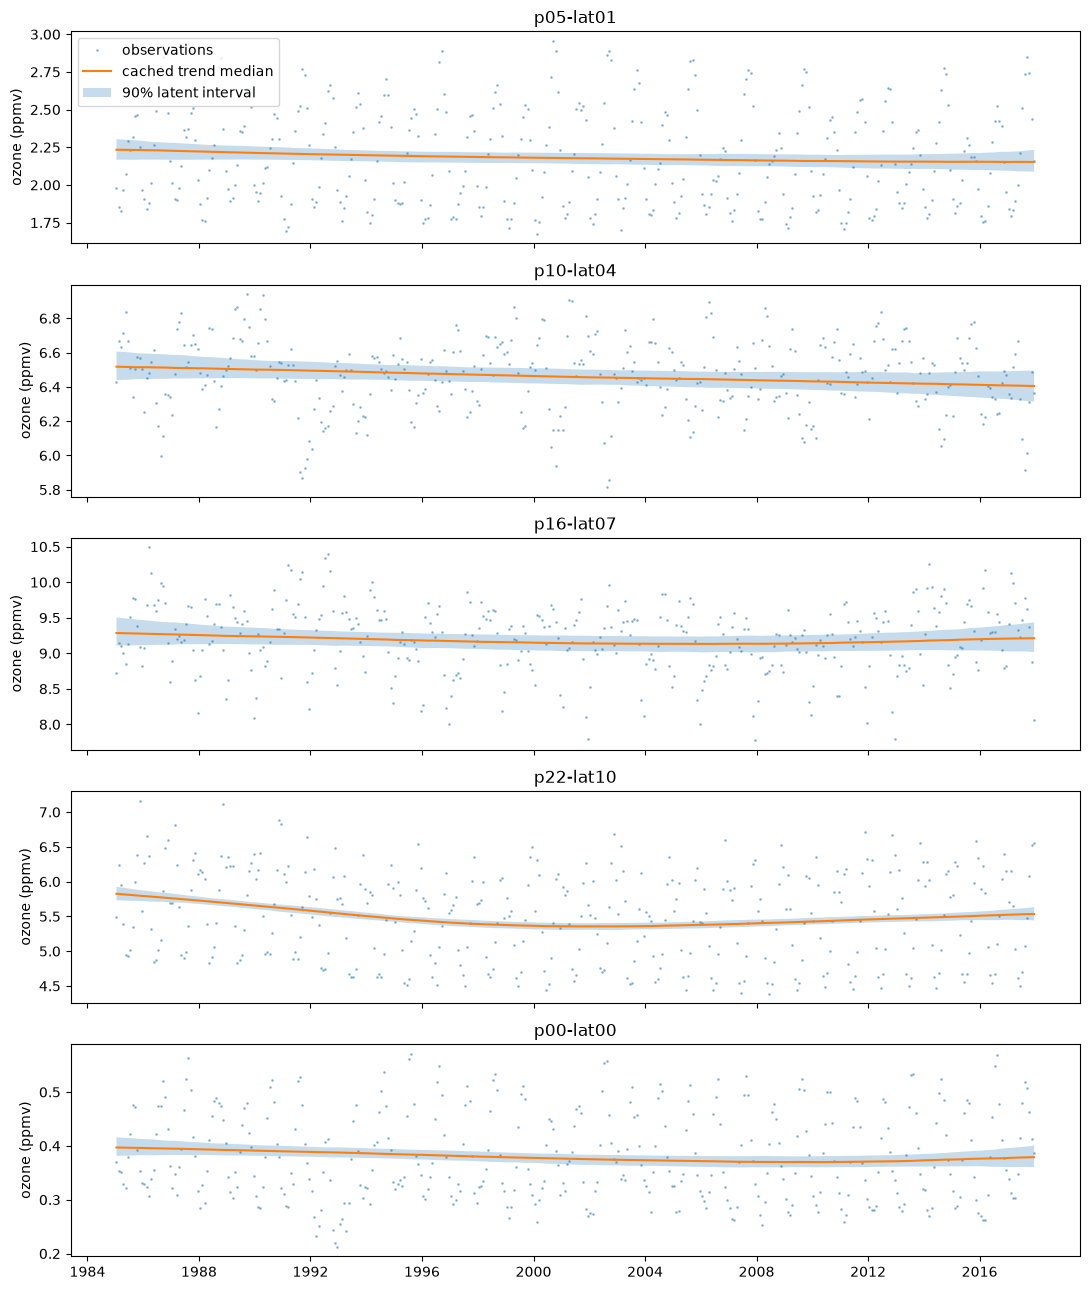

In [10]:
fig, axes = plt.subplots(5, 1, figsize=(11, 13), sharex=True)
for i, ax in enumerate(axes):
    q = science["component_quantiles"][i, :, :, 0]
    ax.plot(data.time, data.isel(panel=i), ".", ms=2, alpha=.4, label="observations")
    ax.plot(data.time, q[1], label="cached trend median")
    ax.fill_between(data.time.values, q[0], q[2], alpha=.25, label="90% latent interval")
    ax.set_title(provenance["panel_ids"][i]); ax.set_ylabel("ozone (ppmv)")
axes[0].legend(); fig.tight_layout(); plt.show()

## Batching consistency and MPI migration

`fit_grid` batches independent cells and walkers in one process. It replaces the primary `dlm_lat_alt_mpi_run.py`/MPI example workflow without requiring worker launches; the legacy MPI entry point remains available. Each tensor slice is compared with the same panel's individual fit. Permutation/chunking need statistically consistent inference, not identical random draws. The cached results below cover singleton, permutation and 2+3 chunk layouts; chunks also check removal of other independent cells.

In [11]:
validation["layout_comparisons"]

[{'panel': 'p05-lat01',
  'comparison': 'singleton_to_individual',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_ess': 6305.62387286595,
  'point_flags': 0,
  'report': 'reports/01-practical-layout-numba-singleton-p05-lat01-p05-lat01-16000-8192.json',
  'actual_wall_seconds': 16.23161005973816},
 {'panel': 'p10-lat04',
  'comparison': 'singleton_to_individual',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_ess': 5578.590122074126,
  'point_flags': 1,
  'report': 'reports/01-practical-layout-numba-singleton-p10-lat04-p10-lat04-16000-8192.json',
  'actual_wall_seconds': 11.790654182434082},
 {'panel': 'p16-lat07',
  'comparison': 'singleton_to_individual',
  'status': 'PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION',
  'minimum_ess': 4342.296252250108,
  'point_flags': 1,
  'report': 'reports/01-practical-layout-numba-singleton-p16-lat07-p16-lat07-8000-8192.json',
  'actual_wall_seconds': 15.10592007637024},
 {'panel': 'p22-lat10',

Compilation and disposable kernel warmup are recorded separately from sampling. This smoke run is not a throughput or time-to-ESS benchmark. No full-grid speedup is claimed. Larger independent jobs and both spatial/lag fits remain disabled in this default tutorial; the spatial tutorial requires separate pilot/runtime reports and explicit stage-specific panel selections.

## Finite-moment derived summary

The active practical diagnostic profile uses `log(stationary_AR_variance)` for that derived quantity’s mean, SD and quantile checks. The unchanged AR model has an infinite raw stationary-variance SD, so a finite sample SD is not a population-SD qualification. Raw values and earlier failed or passed finite-window diagnostics remain available. Model parameters, priors, ozone/trend/coefficient checks and scientific effect-size bands are unchanged. All 25 saved vanilla comparisons pass the affected log-summary checks without new MCMC; one selected subset failure was resolved using its complete saved window and remains recorded. Other scientific evidence retains its original scope.

## Explicit harmonic preprocessing

No-seasonal model inputs: the selected policy fits annual and semiannual harmonics jointly with an intercept and linear trend over 1985–2017. Only the centered harmonic component is removed; the observed mean and fitted trend are retained. Apply the same procedure separately to ozone and each predictor. Measurement uncertainties are unchanged; inference is conditional on the estimated fixed cycle. This changes the input target and range normalization, so new matching Stan/affine caches are required. Original no-seasonal fits on seasonal BASIC data remain superseded. Seasonal-model cached science below is unaffected.

In [12]:
harmonic_ozone = dlmmc.deseasonalize_harmonics(data)
harmonic_regressors = dlmmc.deseasonalize_harmonics(regressors)
np.testing.assert_allclose(harmonic_ozone.deseasonalized + harmonic_ozone.seasonal_component,
                           data, rtol=0, atol=2e-14)
np.testing.assert_allclose(harmonic_ozone.deseasonalized.mean("time"), data.mean("time"), atol=2e-14)
assert harmonic_ozone.deseasonalized.sizes["panel"] == 5
# Preparation only: no posterior run or additional spatial scope is launched.
corrected = dlmmc.prepare_data(harmonic_ozone.deseasonalized,
    harmonic_regressors.deseasonalized, uncertainty=uncertainty,
    model="vanilla_ar1_noseasonal", dtype="float64")
assert corrected.cells == 5
try:
    dlmmc.prepare_data(data, regressors, uncertainty=uncertainty, model="vanilla_ar1_noseasonal")
except ValueError as error:
    print("Expected raw seasonal-input guard:", error)
else:
    raise AssertionError("No-seasonal preparation must reject undeclared data")
print(harmonic_ozone.attrs["seasonal_preprocessing"])
print("Corrected prepared checksum:", corrected.checksum)
print("This is preprocessing smoke evidence, not posterior qualification.")

Expected raw seasonal-input guard: No-seasonal models require explicitly deseasonalised data. Use deseasonalize_harmonics, or document external preprocessing with seasonality and seasonal_preprocessing attributes. Synthetic data generated without seasonality require an explicit declaration.
{"harmonics": [1, 2], "method": "annual_semiannual_ols_v1", "missing": "finite_observations_only", "nuisance": ["intercept", "linear_trend"], "period_months": 12, "phase_origin": "1985-01-15T12:00:00.000000000", "subtract": "harmonics_only_centered_over_observed_months", "uncertainty": "conditional_on_fixed_fitted_cycle", "weights": "uniform", "window_end": "2017-12-15T12:00:00.000000000", "window_start": "1985-01-15T12:00:00.000000000"}
Corrected prepared checksum: bdd0269ff8181884518e62d251938c631f1458d56ac0acd5a136879cc229b587
This is preprocessing smoke evidence, not posterior qualification.


## Measured small-panel performance

Saved local timing evidence below separates fixed-parameter batching throughput from sample efficiency and time to usable scientific output. Compilation and disposable warmup are excluded from timed kernel trials. Initialization and MCMC burn-in remain part of fit time. Short-run ESS estimates do not pass when reliability checks fail; unresolved tuning retains64walkers per half (128total). Float32/device research measurements preserve all numerical failures and do not certify GPU inference. No full-grid timing or automatic benchmark execution occurs here.

In [13]:
performance_path = bundle / "performance-stage04.json"
current_provenance = json.loads((bundle / "provenance.json").read_text())
assert hashlib.sha256(performance_path.read_bytes()).hexdigest() == current_provenance["stage04_performance_sha256"]
performance = json.loads(performance_path.read_text())
rows = []
for name, evidence_row in performance.items():
    if name.startswith("04-kernel-"):
        d = evidence_row["data"]
        rows.append({k: d.get(k) for k in ["backend", "device", "dtype", "cells", "status", "median_seconds", "median_batching_speedup", "peak_process_rss_bytes"]})
local_timings = pd.DataFrame(rows)
display(local_timings)
display(performance["04-sampler-tuning.json"]["data"])
display(pd.DataFrame(performance["04-baselines.json"]["data"]["rows"]))
print(performance["04-baselines.json"]["data"]["limitations"])
print("Cached measurements with source-report hashes; no benchmark or tuning rerun.")

,backend,device,dtype,cells,status,median_seconds,median_batching_speedup,peak_process_rss_bytes
0,torch,cuda,float32,1,UNAVAILABLE,NaN,NaN,NaN
1,torch,cuda,float64,1,UNAVAILABLE,NaN,NaN,NaN
2,torch,mps,float32,1,MEASURED_KERNEL_ONLY,0.058272,0.988189,523845632.0
3,torch,mps,float32,1,UNAVAILABLE,NaN,NaN,NaN
4,torch,mps,float32,5,MEASURED_KERNEL_ONLY,0.060548,4.869820,523632640.0
5,torch,mps,float32,5,UNAVAILABLE,NaN,NaN,NaN
6,numba,cpu,float64,1,MEASURED_KERNEL_ONLY,0.005418,1.009597,401211392.0
7,numba,cpu,float64,5,MEASURED_KERNEL_ONLY,0.025994,1.036877,414089216.0
8,torch,cpu,float32,1,MEASURED_KERNEL_ONLY,0.041219,1.009335,366624768.0
9,torch,cpu,float32,5,MEASURED_KERNEL_ONLY,0.148075,1.406901,366739456.0


[{'cells': 1,
  'status': 'INCONCLUSIVE_KEEP_VALIDATED_64_HALF_BASELINE',
  'actual_wall_seconds': 635.6607743748464,
  'peak_process_rss_bytes': 1458405376,
  'candidates': [{'half_walkers': 64,
    'total_walkers': 128,
    'status': 'INCONCLUSIVE',
    'time_to_target_seconds': None,
    'actual_wall_seconds': 215.2151499169413,
    'excluded_compilation_and_disposable_seconds': 0.17389316717162728,
    'post_compilation_censored_seconds': 215.04125674976967},
   {'half_walkers': 128,
    'total_walkers': 256,
    'status': 'INCONCLUSIVE',
    'time_to_target_seconds': None,
    'actual_wall_seconds': 210.20120662497357,
    'excluded_compilation_and_disposable_seconds': 0.09602070855908096,
    'post_compilation_censored_seconds': 210.10518591641448},
   {'half_walkers': 256,
    'total_walkers': 512,
    'status': 'INCONCLUSIVE',
    'time_to_target_seconds': None,
    'actual_wall_seconds': 210.2062863749452,
    'excluded_compilation_and_disposable_seconds': 0.15718541713431478,

,workflow,sampling_with_initialization_seconds,post_compilation_executed_pipeline_seconds,parameter_ess,output_ess,output_phase_seconds,compile_disposable_seconds,settings,parameter_ess_per_sampling_second,output_ess_per_executed_pipeline_second,executed_pipeline_ratio_to_affine
0,Affine + matched deferred outputs,178.983990,359.975880,41191.557743,5833.320531,77.599148,0.172998,4 independent ensembles;128 total walkers;100 ...,230.141019,16.204754,1.000000
1,Parameter-only CmdStan + matched deferred outputs,324.350267,398.500912,3155.588246,2915.643223,73.354506,6.711887,4 chains;parallel2;500 warmup +3000 retained/c...,9.728952,7.316528,1.107021
2,Original CmdStan with generated outputs,345.563126,379.386200,3165.441374,3165.441374,32.445849,7.441800,4 chains;parallel2;500 warmup +3000 retained/c...,9.160241,8.343586,1.053921


['Single controlled seed set, one frozen panel; no guarantee of general speedup', 'Pipeline sum includes executed diagnostics/I/O and first review wait, excludes inter-job conversational gaps; not uninterrupted end-to-end latency', 'Affine elapsed including actual final review is recorded separately; manual review latency prevents a clean unattended wall-time speedup', 'All variants pass practical ESS2000; achieved ESS differs, no extrapolated exact time-to-2000', 'Affine/parameter Stan reconstruct2048draws/run; original Stan outputsall12000. Prespecified scientific summaries match; output contracts differ', 'Original audit includes validated CDF supplement; sampled signs also pass', 'Initialization/warmup included; all known compilation/disposable warmup excluded; bootstrap comparisons ran concurrently and their times are excluded from performance ratios', 'Kernel GPU timings do not qualify GPU scientific inference']
Cached measurements with source-report hashes; no benchmark or tunin

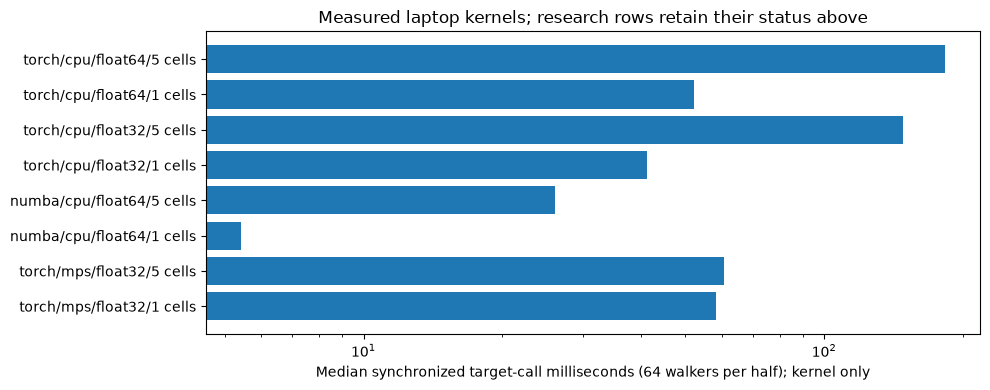

In [14]:
shown = local_timings.dropna(subset=["median_seconds"]).copy()
if len(shown):
    labels = shown.apply(lambda r: str(r["backend"])+"/"+str(r["device"])+"/"+str(r["dtype"])+"/"+str(r["cells"])+" cells", axis=1)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(labels, shown["median_seconds"] * 1000)
    ax.set_xscale("log")
    ax.set_xlabel("Median synchronized target-call milliseconds (64 walkers per half); kernel only")
    ax.set_title("Measured laptop kernels; research rows retain their status above")
    fig.tight_layout()
    plt.show()